HTTP Status Frequency: {'404': 18, '200': 82, '304': 30, '500': 20}
IP Frequency: {'192.168.1.19': 14, '192.168.1.24': 8, '192.168.1.13': 9, '192.168.1.15': 9, '192.168.1.11': 8, '192.168.1.20': 11, '192.168.1.23': 10, '192.168.1.10': 7, '192.168.1.21': 8, '192.168.1.25': 13, '192.168.1.12': 7, '192.168.1.14': 7, '192.168.1.17': 10, '192.168.1.16': 6, '192.168.1.18': 14, '192.168.1.22': 9}


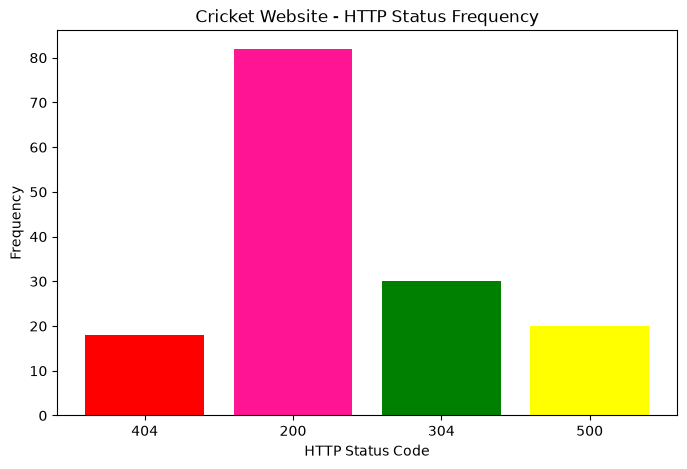

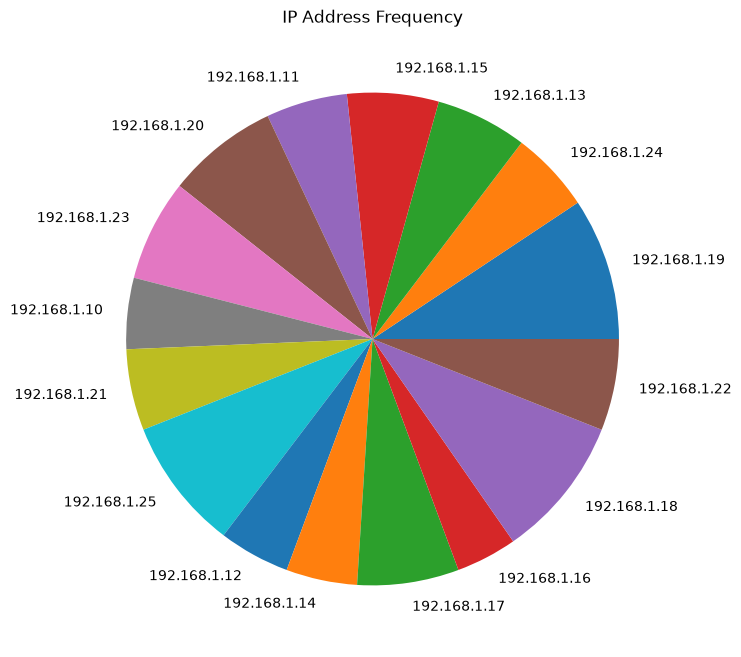

In [10]:
import os
import csv
import pandas as pd
import matplotlib.pyplot as plt

ip = []
http_status = []
mydict = {}
path = "C:\\Users\\dines\\Downloads"
filename = "cricket_project.log"

with open(os.path.join(path, filename), "r") as f:
    for each_line in f:
        mylist = each_line.split(" ")

        ip.append(mylist[3])
        http_status.append(mylist[8].strip())

#print("IP Addresses:", ip)
#print("HTTP Status:", http_status)

def frequency(mylist):

    mydict = {}

    for each in mylist:
        if each not in mydict:
            mydict[each] = 1
        else:
            mydict[each] += 1

    return mydict

def write_to_csv(mydict, filename):

    with open(os.path.join(path, filename), "w", newline="") as f:

        writer = csv.writer(f)
        writer.writerow(["Sno", "Value", "Frequency"])

        Sno = 1

        for each, count in mydict.items():
            writer.writerow([Sno, each, count])
            Sno += 1
x = frequency(http_status)
print("HTTP Status Frequency:", x)

write_to_csv(x, "cricket_status_frequency.csv")
y = frequency(ip)
print("IP Frequency:", y)

write_to_csv(y, "cricket_ip_frequency.csv")

# Convert dictionary into DataFrame

df_status = pd.DataFrame(
    list(x.items()),
    columns=["HTTP_Status", "Frequency"]
)

df_ip = pd.DataFrame(
    list(y.items()),
    columns=["IP_Address", "Frequency"]
)

# 1. HTTP Status Frequency - Bar Chart

plt.figure(figsize=(8, 5))
c=["red","deeppink","green","yellow"]
plt.bar(df_status["HTTP_Status"], df_status["Frequency"],color=c)

plt.xlabel("HTTP Status Code")
plt.ylabel("Frequency")
plt.title("Cricket Website - HTTP Status Frequency")

plt.show()

# 2. IP Address Frequency - Bar Chart

plt.figure(figsize=(8,8))

plt.pie(df_ip["Frequency"], labels=df_ip["IP_Address"])

plt.title("IP Address Frequency")

plt.show()

# Save DataFrames into CSV

df_status.to_csv(
    os.path.join(path, "cricket_status_frequency.csv"),
    index=False
)

df_ip.to_csv(
    os.path.join(path, "cricket_top10_ip_frequency.csv"),
    index=False
)

